# Final Part 2 stopping-reason analysis with reference predictions

Recompute the reason-dependent analysis without fitting any model. True labels override predictions. All 131 old unresolved phase rows are resolved as hybrid pseudo-labels; absent Part 1 records remain separate. Multi-label categories overlap. Inputs are the supplied datasets and saved authoritative Part 1/Part 2 predictions. The complete matching, aggregation, verification and figure code is embedded.


In [1]:
from pathlib import Path
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'part1-data').is_dir() and (p / 'part2-data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the repository or assembled midterm folder with both data directories.')
RUN_FULL = False
REPRO_ROOT = ROOT / 'deliverables/reproduced'
REPRO_ROOT.mkdir(parents=True, exist_ok=True)
print('Mode:', 'full fresh reproduction' if RUN_FULL else 'read-only artifact verification; no training')



Mode: read-only artifact verification; no training


In [2]:
import hashlib
import json
import numpy as np
import pandas as pd
REASONS=('Safety','Funding','Efficacy','Recruitment','Other')
PHASES=('I','II','III')
THRESHOLD=.5
NO_REASON='no recorded stopping reason'
UNAVAILABLE='matched Part 1 record; reasons unavailable'
OUT=REPRO_ROOT / 'integrated_error_analysis'
OUT.mkdir(parents=True,exist_ok=True)


In [3]:
from sklearn.metrics import log_loss, f1_score, roc_auc_score, average_precision_score


## Matching and summary implementation (original unchanged evaluation logic)


In [4]:
def match_unsuccessful(validation, outcome, reasons):
    assert validation.ID.is_unique and not validation.duplicated(['trial_id', 'phase']).any()
    assert validation.trial_id.str.fullmatch(r'TR\d+').all()
    assert validation.ID.eq(validation.trial_id + '_' + validation.phase).all()
    assert set(validation.phase) == set(PHASES)
    assert validation.label.isin([0, 1]).all()
    assert np.isfinite(validation.probability).all() and validation.probability.between(0, 1).all()
    assert validation.predicted_label.eq((validation.probability >= THRESHOLD).astype(int)).all()
    # Verify saved predictions against the actual outcome validation split, not ID format alone.
    check = validation.merge(outcome[['ID', 'trial_id', 'phase', 'label']], on='ID',
                             suffixes=('', '_actual'), validate='one_to_one', how='outer', indicator=True)
    assert check._merge.eq('both').all()
    for col in ('trial_id', 'phase', 'label'):
        assert check[col].eq(check[col + '_actual']).all()
    unsuccessful = validation.loc[validation.label.eq(0)].copy()
    joined = unsuccessful.merge(reasons, on='trial_id', how='left', validate='many_to_one', indicator=True)
    joined['part1_match'] = joined.pop('_merge').eq('both')
    joined['reason_source'] = joined.reason_source.fillna('no_record')
    joined['part1_split'] = joined.part1_split.fillna('none')
    assert not joined.duplicated(['trial_id', 'phase']).any()
    return joined


In [5]:
def summarize(group):
    n = len(group)
    fp = int(group.predicted_label.sum())
    return dict(n_trials=n, n_predicted_success=fp,
                false_success_rate=fp / n if n else np.nan,
                mean_predicted_success_probability=float(group.probability.mean()) if n else np.nan,
                n_ground_truth=int(group.reason_source.eq('ground_truth').sum()),
                n_predictions=int(group.reason_source.eq('prediction').sum()),
                n_no_record=int(group.reason_source.eq('no_record').sum()),
                n_reasons_unavailable=int(group.reason_source.eq('unavailable').sum()))


In [6]:
def summarize_groups(joined):
    rows, coverage, unresolved, source_rows = [], [], [], []
    for phase in PHASES:
        phase_rows = joined.loc[joined.phase.eq(phase)]
        coverage.append(dict(phase=phase, **summarize(phase_rows)))
        unresolved.append(dict(phase=phase, reason_group=UNAVAILABLE,
                               **summarize(phase_rows.loc[phase_rows.reason_source.eq('unavailable')])))
        for reason in (*REASONS, NO_REASON):
            mask = ~phase_rows.part1_match if reason == NO_REASON else phase_rows[reason].eq(1).fillna(False)
            group = phase_rows.loc[mask]
            rows.append(dict(phase=phase, reason_group=reason, **summarize(group)))
            for source in ('ground_truth', 'prediction', 'no_record'):
                source_rows.append(dict(phase=phase, reason_group=reason, reason_source=source,
                                        **summarize(group.loc[group.reason_source.eq(source)])))
    return tuple(pd.DataFrame(r) for r in (rows, coverage, unresolved, source_rows))


In [7]:
def evaluate(frame, probabilities):
    p = np.asarray(probabilities, dtype=float)
    if p.shape != (len(frame),) or not np.isfinite(p).all() or not ((p >= 0) & (p <= 1)).all():
        raise ValueError('Expected one finite probability per row in [0, 1]')
    result = {}
    for phase in ('overall', *PHASES):
        mask = np.ones(len(frame), dtype=bool) if phase == 'overall' else frame.phase.eq(phase).to_numpy()
        y, pred = frame.label.to_numpy()[mask], p[mask]
        result[f'{phase}_n'] = len(y)
        if not len(y):
            for metric in ('log_loss', 'f1', 'roc_auc', 'average_precision'):
                result[f'{phase}_{metric}'] = np.nan
            continue
        result[f'{phase}_log_loss'] = log_loss(y, pred, labels=[0, 1])
        result[f'{phase}_f1'] = f1_score(y, pred >= THRESHOLD, zero_division=0)
        both = len(np.unique(y)) == 2
        result[f'{phase}_roc_auc'] = roc_auc_score(y, pred) if both else np.nan
        result[f'{phase}_average_precision'] = average_precision_score(y, pred) if both else np.nan
    result['phase_macro_log_loss'] = np.mean([result[f'{p}_log_loss'] for p in PHASES])
    return result


In [8]:
def markdown_table(frame):
    def fmt(v):
        return f'{v:.5f}' if isinstance(v, float) else str(v)
    return '\n'.join(['| ' + ' | '.join(map(str, frame.columns)) + ' |',
                      '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |',
                      *['| ' + ' | '.join(fmt(v) for v in row) + ' |' for row in frame.itertuples(index=False, name=None)]])


## Authoritative Part 1 provenance, recomputation and old/new comparison

Use observed train/validation labels, hybrid pseudo-labels for masked train rows, and hybrid test predictions. No labels are inferred from outcome predictions. Original results remain in part2/outputs/; new tables are written separately.


In [9]:
def authoritative_reasons(root):
    parts = {s: pd.read_csv(root / 'part1-data' / f'part1_{s}.csv') for s in ('train','val','test')}
    train_predictions = pd.read_csv(root / 'part1-results/knn-experiment/best_augmented_training_labels.csv')
    test_predictions = pd.read_csv(root / 'part1-results/knn-experiment/best_augmented_candidate_submission.csv')
    assert train_predictions.ID.is_unique and set(train_predictions.ID) == set(parts['train'].ID)
    assert test_predictions.ID.is_unique and set(test_predictions.ID) == set(parts['test'].ID)
    assert train_predictions[list(REASONS)].isin([0, 1]).all().all()
    assert set(train_predictions.label_source) == {'observed_train', 'pseudo_train'}
    estimated = train_predictions.set_index('ID')
    test_estimated = test_predictions.set_index('ID')
    records = []
    for split, frame in parts.items():
        assert frame.ID.is_unique and frame.ID.str.fullmatch(r'TR\d+').all()
        for _, row in frame.iterrows():
            if split in ('train', 'val'):
                valid = row[list(REASONS)].isin([0, 1]).all()
                assert valid or row[list(REASONS)].eq(-100).all()
            else:
                valid = False
            if valid:
                values = row[list(REASONS)].astype(int).to_dict()
                source = f'observed_{split}'
                if split == 'train':
                    assert estimated.loc[row.ID, 'label_source'] == 'observed_train'
                    assert all(estimated.loc[row.ID, r] == values[r] for r in REASONS)
            elif split == 'train':
                assert estimated.loc[row.ID, 'label_source'] == 'pseudo_train'
                values = estimated.loc[row.ID, list(REASONS)].astype(int).to_dict()
                source = 'pseudo_train'
            else:
                text = test_estimated.loc[row.ID, 'Predicted']
                assert isinstance(text, str) and text.strip()
                labels = text.split()
                assert set(labels) <= set(REASONS) and len(labels) == len(set(labels))
                values = {reason: int(reason in labels) for reason in REASONS}
                source = 'predicted_part1_test'
            records.append(dict(trial_id=row.ID, part1_split=split,
                reason_source='ground_truth' if valid else 'prediction',
                label_source=source, **values))
    lookup = pd.DataFrame(records)
    assert lookup.trial_id.is_unique and len(lookup) == 1561
    return lookup


In [10]:
def reconcile(root=ROOT, out=OUT):
    out.mkdir(parents=True, exist_ok=True)
    lookup = authoritative_reasons(root)
    lookup.to_csv(out / 'authoritative_reason_lookup.csv', index=False)
    outcome = pd.read_csv(root / 'part2-data/outcome_val.csv')
    original = pd.read_csv(root / 'part2/outputs/best_validation_predictions.csv')
    calibrated = pd.read_csv(root / 'part2/calibration_outputs/validation_predictions.csv')
    candidates = {'baseline': original}
    for name in ('sigmoid_pooled', 'sigmoid_by_phase'):
        frame = calibrated.loc[calibrated.candidate.eq(name)].reset_index(drop=True).copy()
        assert frame.ID.equals(outcome.ID)
        candidates[name] = frame
    old_audit = pd.read_csv(root / 'part2/outputs/stopping_reason_trial_audit.csv')
    old_unknown = old_audit.loc[old_audit.reason_source.eq('unavailable')]
    assert len(old_unknown) == 131 and old_unknown.trial_id.nunique() == 113
    groups_all, coverage_all, audit_all, metric_rows = [], [], [], []
    sources_all = []
    for name, predictions in candidates.items():
        joined = match_unsuccessful(predictions, outcome, lookup)
        joined['label_source'] = joined.label_source.fillna('no_recorded_stopping_reason')
        groups, coverage, unresolved, sources = summarize_groups(joined)
        assert unresolved.n_trials.sum() == 0
        assert len(joined) == 452 and joined.trial_id.nunique() == 398
        resolved = joined.merge(old_unknown[['ID']], on='ID', validate='one_to_one')
        assert len(resolved) == 131 and resolved.reason_source.eq('prediction').all()
        assert resolved.label_source.eq('pseudo_train').all()
        assert coverage.n_ground_truth.sum() == 27
        assert coverage.n_predictions.sum() == 171 and coverage.n_no_record.sum() == 254
        # Independent row-level verification, separate from the group summary helper.
        for row in groups.itertuples(index=False):
            phase = joined.loc[joined.phase.eq(row.phase)]
            subset = phase.loc[~phase.part1_match] if row.reason_group == 'no recorded stopping reason' else phase.loc[phase[row.reason_group].eq(1)]
            assert len(subset) == row.n_trials
            count = int((subset.probability >= .5).sum())
            assert count == row.n_predicted_success
            if len(subset):
                assert np.isclose(row.false_success_rate, count / len(subset))
                assert np.isclose(row.mean_predicted_success_probability, subset.probability.mean())
            else:
                assert pd.isna(row.false_success_rate)
        for table, collection in [(groups, groups_all), (coverage, coverage_all), (joined, audit_all), (sources, sources_all)]:
            table['candidate'] = name
            collection.append(table)
        metrics = evaluate(outcome, predictions.probability.to_numpy())
        metric_rows.append(dict(candidate=name, **metrics))
    groups = pd.concat(groups_all, ignore_index=True)
    coverage = pd.concat(coverage_all, ignore_index=True)
    audits = pd.concat(audit_all, ignore_index=True)
    pd.concat(sources_all, ignore_index=True).to_csv(out / 'reason_groups_by_source.csv', index=False)
    groups.to_csv(out / 'reason_groups.csv', index=False)
    coverage.to_csv(out / 'coverage.csv', index=False)
    audits.to_csv(out / 'unsuccessful_trial_audit.csv', index=False)
    baseline_audit = audits.loc[audits.candidate.eq('baseline')]
    baseline_audit.loc[baseline_audit.ID.isin(old_unknown.ID)].to_csv(out / 'resolved_previous_unknowns.csv', index=False)
    old_groups = pd.read_csv(root / 'part2/outputs/stopping_reason_groups.csv')
    comparison = old_groups.merge(groups.loc[groups.candidate.eq('baseline')], on=['phase','reason_group'], suffixes=('_old','_integrated'), validate='one_to_one')
    for col in ('n_trials','n_predicted_success','false_success_rate','mean_predicted_success_probability'):
        comparison[col + '_change'] = comparison[col + '_integrated'] - comparison[col + '_old']
    comparison.to_csv(out / 'old_vs_integrated_baseline.csv', index=False)
    pd.DataFrame(metric_rows).to_csv(out / 'unchanged_outcome_metrics.csv', index=False)
    best_comparison = groups.loc[groups.candidate.eq('baseline')].merge(
        groups.loc[groups.candidate.eq('sigmoid_pooled')], on=['phase','reason_group'], suffixes=('_baseline','_calibrated'),validate='one_to_one')
    best_comparison.to_csv(out / 'baseline_vs_pooled_calibration.csv', index=False)
    input_files = ['part1-results/knn-experiment/best_augmented_training_labels.csv',
        'part1-results/knn-experiment/best_augmented_candidate_submission.csv',
        'part2/outputs/best_validation_predictions.csv','part2/calibration_outputs/validation_predictions.csv',
        *[f'part1-data/part1_{s}.csv' for s in ('train','val','test')], 'part2-data/outcome_val.csv']
    metadata = dict(part1_source='origin/main final kmeans_knn_hybrid (3 uniform neighbors)',
        no_model_training=True, threshold=.5, previously_unresolved_phase_rows=131,
        previously_unresolved_unique_trials=113, resolved_as_predictions=131,
        remaining_unresolved_phase_rows=0,
        ground_truth_rows=27,predicted_rows=171,no_record_rows=254,
        hashes={p:hashlib.sha256((root / p).read_bytes()).hexdigest() for p in input_files})
    (out / 'analysis_metadata.json').write_text(json.dumps(metadata, indent=2))
    report = ['# Integrated stopping-reason error analysis', '',
        'Part 1 is the final origin/main hybrid. Part 2 probabilities are exactly the frozen original Part 2 source artifacts. '
        'Only true outcome label=0 rows are analyzed; probability >=0.5 is a false success. '
        'Visible training/validation reasons take precedence over predictions. Masked training reasons now use '
        'the reference saved hybrid pseudo-labels; test reasons use the hybrid’s submitted predictions. '
        'Root part1_submission.csv and part1-results/reason_lookup.csv describe earlier models and are not used.', '',
        '**All 131 previously unresolved phase rows (113 trials) are now covered by predictions, not truth.** '
        'There remain 27 rows with true reasons, 171 with predicted reasons and 254 without a Part 1 record. '
        'No record is not a claim of successful completion. Multi-label categories overlap; each trial appears '
        'at most once per phase/group. Empty groups have undefined rates.', '',
        '## Coverage (baseline; membership identical for calibrated candidates)', '',
        markdown_table(coverage.loc[coverage.candidate.eq('baseline')]), '',
        '## All candidate group metrics', '', markdown_table(groups), '',
        '## Changes from original original baseline analysis', '',
        markdown_table(comparison[['phase','reason_group','n_trials_old','n_trials_integrated','false_success_rate_old','false_success_rate_integrated']]), '',
        'Reason-specific changes arise from expanded coverage and replacement of older test-reason predictions, '
        'not changed outcome probabilities. No-record group membership is unchanged. '
        'Pseudo-labels and test predictions have errors; larger groups improve descriptive denominators but '
        'do not turn inferred reasons into ground truth.', '',
        '## Baseline versus the retained pooled calibration', '',
        markdown_table(best_comparison[['phase','reason_group','n_trials_baseline','false_success_rate_baseline','false_success_rate_calibrated']]), '',
        'Calibration optimizes probability quality, not every thresholded subgroup rate. '
        'The same integrated group membership is used before/after calibration. Full subgroup provenance is '
        'retained in unsuccessful_trial_audit.csv and reason_groups_by_source.csv. No reason label or embedding '
        'enters the outcome classifier or calibrator.', '']
    (out / 'analysis_report.md').write_text('\n'.join(report))
    return groups, coverage, comparison


In [11]:
def figures(groups, out=OUT):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    names = ['Safety','Funding','Efficacy','Recruitment','Other','no recorded stopping reason']
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
    for ax, phase in zip(axes, ('I','II','III')):
        for offset, name in [(-.18,'baseline'),(.18,'sigmoid_pooled')]:
            rows = groups.loc[groups.phase.eq(phase) & groups.candidate.eq(name)].set_index('reason_group').reindex(names)
            ax.bar(np.arange(6)+offset, rows.false_success_rate, width=.36, label=name)
        ax.set_xticks(range(6), ['Safety','Funding','Efficacy','Recruitment','Other','No record'], rotation=55, ha='right')
        ax.set(title=f'Phase {phase}', ylim=(0,1))
    axes[0].set_ylabel('False-success fraction among unsuccessful trials')
    axes[2].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(out / 'integrated_reason_errors.png', dpi=150)
    fig.savefig(out / 'integrated_reason_errors.pdf')
    plt.close(fig)


In [12]:
groups,coverage,comparison=reconcile(ROOT,OUT)
figures(groups,OUT)
display(coverage)
display(groups)
display(comparison[["phase","reason_group","n_trials_old","n_trials_integrated","false_success_rate_old","false_success_rate_integrated"]])


,phase,n_trials,n_predicted_success,false_success_rate,mean_predicted_success_probability,n_ground_truth,n_predictions,n_no_record,n_reasons_unavailable,candidate
0,I,64,28,0.437500,0.465395,4,32,28,0,baseline
1,II,265,78,0.294340,0.407016,16,105,144,0,baseline
2,III,123,78,0.634146,0.555062,7,34,82,0,baseline
3,I,64,28,0.437500,0.459144,4,32,28,0,sigmoid_pooled
4,II,265,74,0.279245,0.398110,16,105,144,0,sigmoid_pooled
5,III,123,77,0.626016,0.553898,7,34,82,0,sigmoid_pooled
6,I,64,28,0.437500,0.477556,4,32,28,0,sigmoid_by_phase
7,II,265,79,0.298113,0.405595,16,105,144,0,sigmoid_by_phase
8,III,123,70,0.569106,0.530014,7,34,82,0,sigmoid_by_phase


,phase,reason_group,n_trials,n_predicted_success,false_success_rate,mean_predicted_success_probability,n_ground_truth,n_predictions,n_no_record,n_reasons_unavailable,candidate
0,I,Safety,8,4,0.500000,0.491004,1,7,0,0,baseline
1,I,Funding,3,2,0.666667,0.507481,1,2,0,0,baseline
2,I,Efficacy,4,3,0.750000,0.567040,0,4,0,0,baseline
3,I,Recruitment,24,9,0.375000,0.436501,2,22,0,0,baseline
4,I,Other,3,1,0.333333,0.413177,0,3,0,0,baseline
5,I,no recorded stopping reason,28,13,0.464286,0.474435,0,0,28,0,baseline
6,II,Safety,11,3,0.272727,0.406688,1,10,0,0,baseline
7,II,Funding,4,0,0.000000,0.341672,1,3,0,0,baseline
8,II,Efficacy,15,6,0.400000,0.444213,0,15,0,0,baseline
9,II,Recruitment,93,18,0.193548,0.375120,12,81,0,0,baseline


,phase,reason_group,n_trials_old,n_trials_integrated,false_success_rate_old,false_success_rate_integrated
0,I,Safety,2,8,0.500000,0.500000
1,I,Funding,1,3,0.000000,0.666667
2,I,Efficacy,0,4,NaN,0.750000
3,I,Recruitment,7,24,0.285714,0.375000
4,I,Other,3,3,0.666667,0.333333
5,I,no recorded stopping reason,28,28,0.464286,0.464286
6,II,Safety,5,11,0.600000,0.272727
7,II,Funding,2,4,0.000000,0.000000
8,II,Efficacy,3,15,0.333333,0.400000
9,II,Recruitment,31,93,0.193548,0.193548


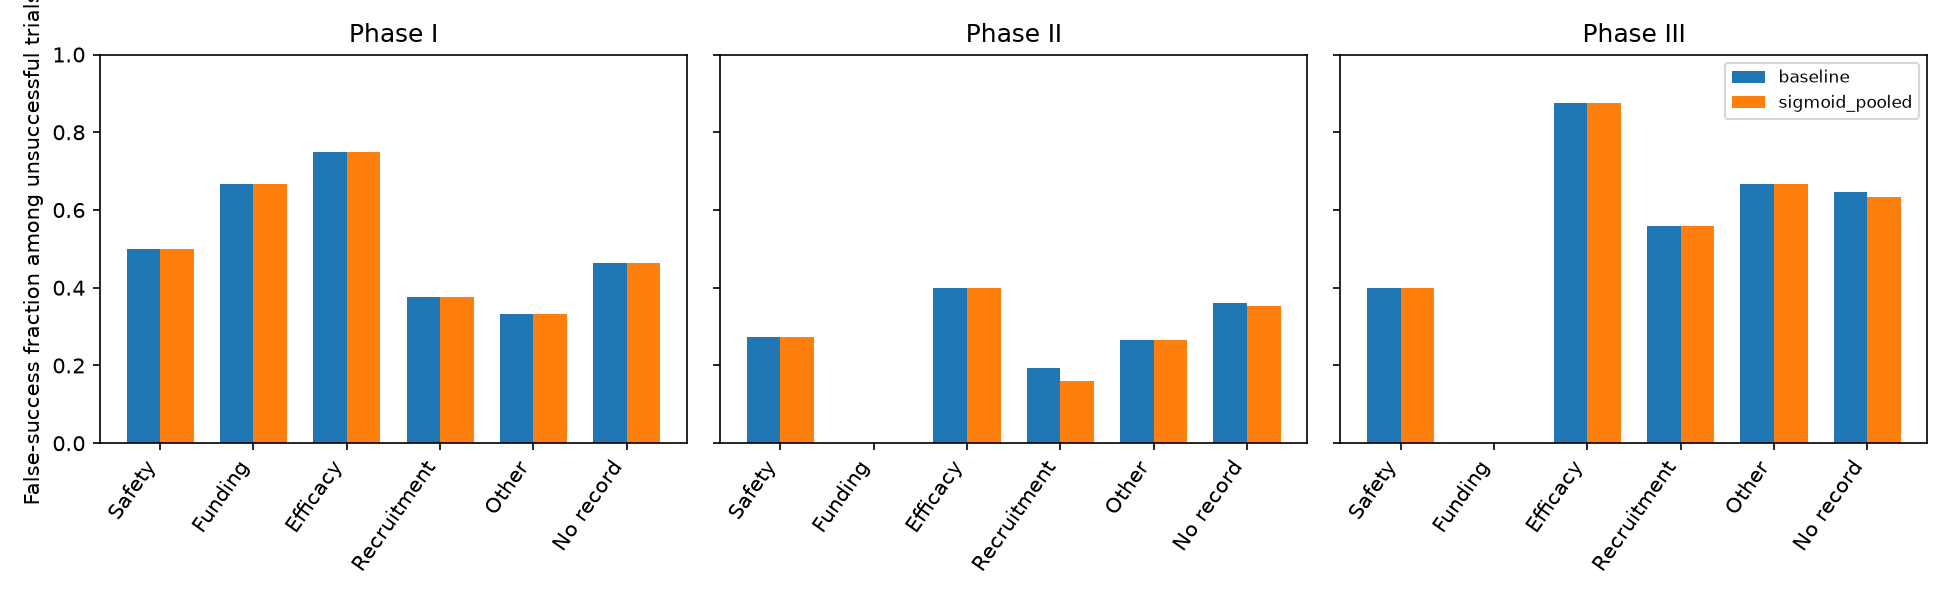

In [13]:
from IPython.display import display, Image
display(Image(filename=str(OUT / "integrated_reason_errors.png")))


## Interpretation

The 113 previously unresolved trials now have predictions, not ground truth. Across 452 unsuccessful phase rows there are 27 true-reason rows, 171 predicted-reason rows and 254 no-record rows; none remain unresolved. Phase II Recruitment changes from 18/93 false successes to 15/93 after pooled calibration. Phase III Efficacy remains 7/8 (all reason labels predicted); Phase III no record changes from 53/82 to 52/82. Empty Phase III Funding rates are undefined. No classifier or calibrator was retrained, and aggregate outcome metrics remain unchanged.
